# Global Superstore: exploratory data analysis
**Yule Liang — BANA409 Assignment 4, Part 1**

Decision-maker: the Global Sales Director. The business question is which markets and product groups need a profitability review before the next sales or promotion decision.

Source: [Fatih İlhan's Kaggle dataset](https://www.kaggle.com/datasets/fatihilhan/global-superstore-dataset). This is an educational retail scenario, not independently verified real-company transactions. The original CSV is retained without sampling.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display

df = pd.read_csv(Path('superstore.csv.gz'))
original_shape = df.shape
df['Order.Date'] = pd.to_datetime(df['Order.Date'])
df['Ship.Date'] = pd.to_datetime(df['Ship.Date'])
print(f'Original file: {original_shape[0]:,} rows, {original_shape[1]} columns')
print(f"Order dates: {df['Order.Date'].min():%Y-%m-%d} to {df['Order.Date'].max():%Y-%m-%d}")
display(df[['Row.ID', 'Order.ID', 'Order.Date', 'Market', 'Category', 'Sub.Category', 'Sales', 'Profit']].head())
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


Original file: 51,290 rows, 27 columns
Order dates: 2011-01-01 to 2014-12-31


,Row.ID,Order.ID,Order.Date,Market,Category,Sub.Category,Sales,Profit
0,36624,CA-2011-130813,2011-01-07,US,Office Supplies,Paper,19,9.3312
1,37033,CA-2011-148614,2011-01-21,US,Office Supplies,Paper,19,9.2928
2,31468,CA-2011-118962,2011-08-05,US,Office Supplies,Paper,21,9.8418
3,31469,CA-2011-118962,2011-08-05,US,Office Supplies,Paper,111,53.2608
4,32440,CA-2011-146969,2011-09-29,US,Office Supplies,Paper,6,3.1104


## 1. Types, missing values, grain, and quality
An order can contain several product lines. Use `Row.ID` for the line identifier and `Order.ID.nunique()` for the number of distinct orders. Negative profit is a business outcome, not an automatic reason to remove a record.


In [2]:
quality = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(), 'unique_values': df.nunique()})
display(quality)
monthly_counts = df.groupby(df['Order.Date'].dt.to_period('M')).size()
expected_months = pd.period_range(df['Order.Date'].min(), df['Order.Date'].max(), freq='M')
checks = pd.Series({
    'Fully duplicated rows': int(df.duplicated().sum()),
    'Repeated Row.ID values': int(df['Row.ID'].duplicated().sum()),
    'Distinct Order.ID values': int(df['Order.ID'].nunique()),
    'Markets': int(df['Market'].nunique()),
    'Countries': int(df['Country'].nunique()),
    'Globally absent months': int(len(expected_months.difference(monthly_counts.index))),
    'Shipping dates earlier than order dates': int((df['Ship.Date'] < df['Order.Date']).sum()),
    'Year inconsistent with order date': int((df['Year'] != df['Order.Date'].dt.year).sum()),
    'Zero-sales lines': int(df['Sales'].eq(0).sum()),
    'Negative-profit lines': int(df['Profit'].lt(0).sum()),
})
display(checks.to_frame('Result'))
display(df.loc[df['Sales'].eq(0), ['Row.ID', 'Order.ID', 'Sales', 'Profit', 'Sub.Category']])
display(df[['Sales', 'Profit', 'Discount', 'Quantity', 'Shipping.Cost']].describe().round(2))


,dtype,missing,unique_values
Category,str,0,3
City,str,0,3636
Country,str,0,147
Customer.ID,str,0,4873
Customer.Name,str,0,795
Discount,float64,0,27
Market,str,0,7
记录数,int64,0,1
Order.Date,datetime64[us],0,1430
Order.ID,str,0,25035


,Result
Fully duplicated rows,0
Repeated Row.ID values,0
Distinct Order.ID values,25035
Markets,7
Countries,147
Globally absent months,0
Shipping dates earlier than order dates,0
Year inconsistent with order date,0
Zero-sales lines,1
Negative-profit lines,12544


,Row.ID,Order.ID,Sales,Profit,Sub.Category
46158,35398,US-2014-102288,0,-1.11,Appliances


,Sales,Profit,Discount,Quantity,Shipping.Cost
count,51290.00,51290.00,51290.00,51290.00,51290.00
mean,246.50,28.61,0.14,3.48,26.38
std,487.57,174.34,0.21,2.28,57.30
min,0.00,-6599.98,0.00,1.00,0.00
25%,31.00,0.00,0.00,2.00,2.61
50%,85.00,9.24,0.00,3.00,7.79
75%,251.00,36.81,0.20,5.00,24.45
max,22638.00,8399.98,0.85,14.00,933.57


There are 51,290 lines and 25,035 distinct order IDs. The 27 source columns have no missing cells; there are no fully duplicated rows or repeated Row.ID values. All 48 calendar months are represented globally, and the Year column agrees with the parsed order date. These checks do not establish accounting accuracy or complete coverage of a real business.

One line has Sales = 0 and Profit = -1.11. It is retained in aggregate profit. Individual line margins with zero sales are undefined and must not be averaged. There are 12,544 negative-profit lines; they are retained because they are central to the business question. Every supplied Sales value is a whole number, so the lost cent-level precision cannot be reconstructed.


## 2. Business metrics and segment relationships
Calculate margin from matching totals for each group. Keep the Profit field as reported: its definition does not justify subtracting shipping cost a second time. Dollar labels follow the source dataset convention rather than an independently verified currency audit.


In [3]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
print(f'Total Sales: ${total_sales:,.2f}')
print(f'Total Profit: ${total_profit:,.2f}')
print(f'Profit Margin: {total_profit / total_sales:.2%}')
print(f"Negative-profit line share: {df['Profit'].lt(0).mean():.2%}")

def group_metrics(column):
    result = df.groupby(column)[['Sales', 'Profit']].sum()
    result['Profit Margin (%)'] = result['Profit'] / result['Sales'].where(result['Sales'] > 0) * 100
    return result.sort_values('Profit').round(2)

display(group_metrics('Market'))
display(group_metrics('Category'))
display(group_metrics('Sub.Category'))
yearly = df.groupby(df['Order.Date'].dt.year)[['Sales', 'Profit']].sum()
yearly['Profit Margin (%)'] = yearly['Profit'] / yearly['Sales'] * 100
yearly['Sales growth (%)'] = yearly['Sales'].pct_change() * 100
yearly['Profit growth (%)'] = yearly['Profit'].pct_change() * 100
display(yearly.round(2))


Total Sales: $12,642,905.00
Total Profit: $1,467,457.29
Profit Margin: 11.61%
Negative-profit line share: 24.46%


,Sales,Profit,Profit Margin (%)
Market,,,
Canada,66932,17817.39,26.62
EMEA,806184,43897.97,5.45
Africa,783776,88871.63,11.34
LATAM,2164687,221643.49,10.24
US,2297354,286397.02,12.47
EU,2938139,372829.74,12.69
APAC,3585833,436000.05,12.16


,Sales,Profit,Profit Margin (%)
Category,,,
Furniture,4110884,285204.72,6.94
Office Supplies,3787330,518473.83,13.69
Technology,4744691,663778.73,13.99


,Sales,Profit,Profit Margin (%)
Sub.Category,,,
Tables,757034,-64083.39,-8.47
Fasteners,83254,11525.42,13.84
Labels,73433,15010.51,20.44
Supplies,243090,22583.26,9.29
Envelopes,170926,29601.12,17.32
Furnishings,385609,46967.43,12.18
Art,372163,57953.91,15.57
Machines,779071,58867.87,7.56
Paper,244307,59207.68,24.23


,Sales,Profit,Profit Margin (%),Sales growth (%),Profit growth (%)
Order.Date,,,,,
2011,2259511,248940.81,11.02,NaN,NaN
2012,2677493,307415.28,11.48,18.50,23.49
2013,3405860,406935.23,11.95,27.20,32.37
2014,4300041,504165.97,11.72,26.25,23.89


The full snapshot has $12,642,905.00 in sales and $1,467,457.29 in reported profit, a margin of 11.61%. Furniture has about $4.11 million in sales but only 6.94% margin; Technology has about 13.99% margin. Tables have -$64,083.39 in reported profit. This supports showing subcategory profit rather than only category sales totals.

EMEA's margin of 5.45% is below the overall margin, supporting a market filter. Canada's margin is higher but its sales base is much smaller: efficiency and scale must be read together. Yearly changes should be assessed alongside seasonal monthly patterns.


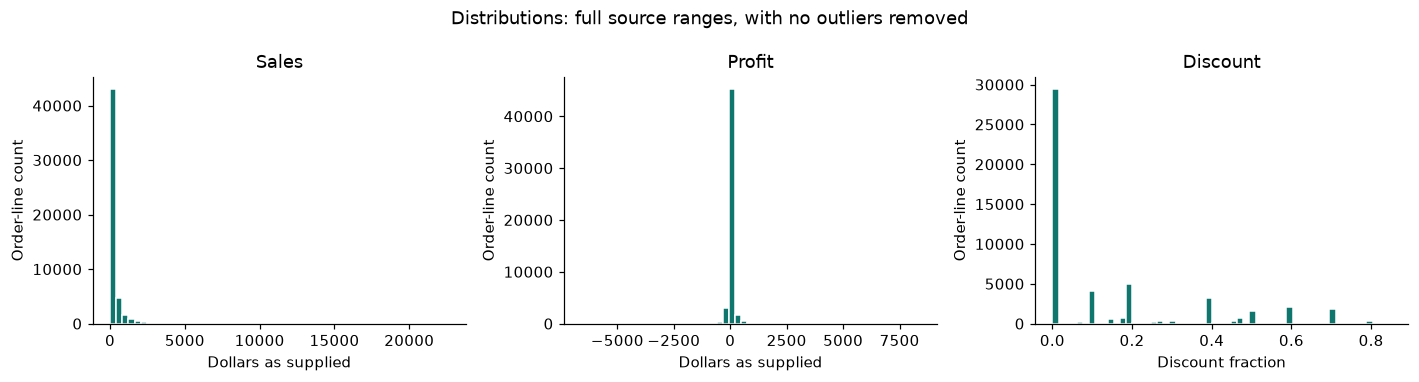

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, column in zip(axes, ['Sales', 'Profit', 'Discount']):
    ax.hist(df[column], bins=55, color='#0f766e', edgecolor='white')
    ax.set_title(column)
    ax.set_ylabel('Order-line count')
    ax.set_xlabel('Discount fraction' if column == 'Discount' else 'Dollars as supplied')
fig.suptitle('Distributions: full source ranges, with no outliers removed')
fig.tight_layout()
plt.show()
plt.close(fig)


Sales are strongly right-skewed, while profit includes substantial negative values. The histogram shows the full ranges; extreme observations are not deleted simply because they are large. Repeated discount levels represent pricing groups, but the data do not contain an experiment that would identify the causal effect of discounts.


In [5]:
discount_band = pd.cut(df['Discount'], bins=[-0.001, 0, 0.1, 0.2, 0.3, 1],
                       labels=['0%', '(0%, 10%]', '(10%, 20%]', '(20%, 30%]', '>30%'])
discount_summary = df.groupby(discount_band, observed=True)[['Sales', 'Profit']].sum()
discount_summary['Profit Margin (%)'] = discount_summary['Profit'] / discount_summary['Sales'] * 100
display(discount_summary.round(2))


,Sales,Profit,Profit Margin (%)
Discount,,,
0%,6992734,1770695.27,25.32
"(0%, 10%]",1962633,338189.26,17.23
"(10%, 20%]",1757296,173254.84,9.86
"(20%, 30%]",382540,-21155.61,-5.53
>30%,1547702,-793526.47,-51.27


The zero-discount group has a margin near 25.32%, while the group above 30% discount has a margin near -51.27%. This motivates checking discount terms when a loss is found. Product and market mix may explain part of the association; no claim is made that removing a discount would recover the observed loss. The discount table stays in this exploration rather than becoming a third dashboard chart.


## 3. Supporting views for the director
Use time trends to locate when a change occurred, then subcategory profit to locate the product group requiring investigation. Keep the sales and profit trend scales separate and labeled.


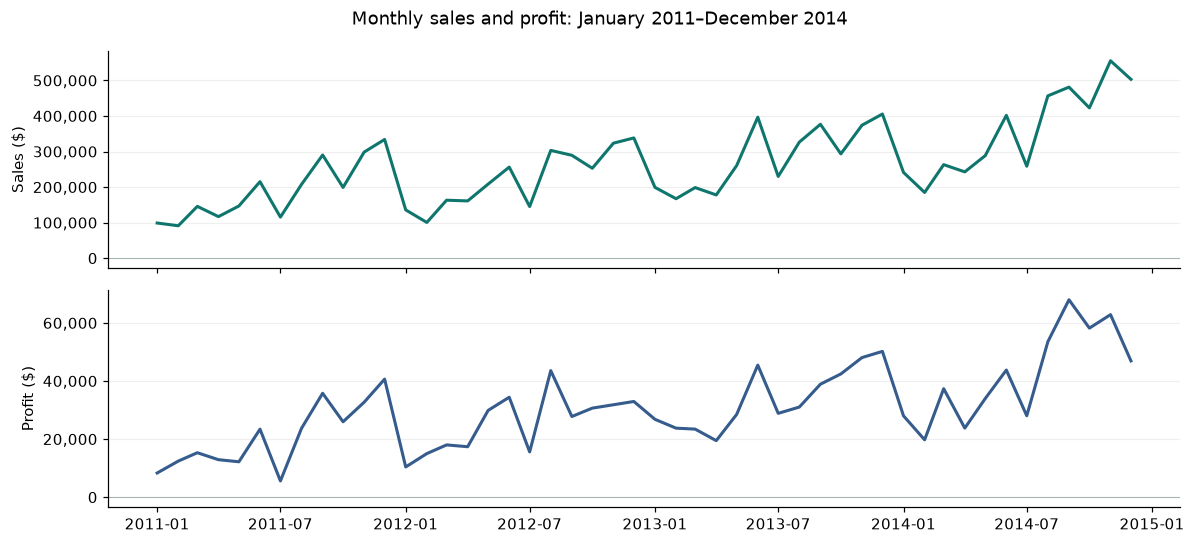

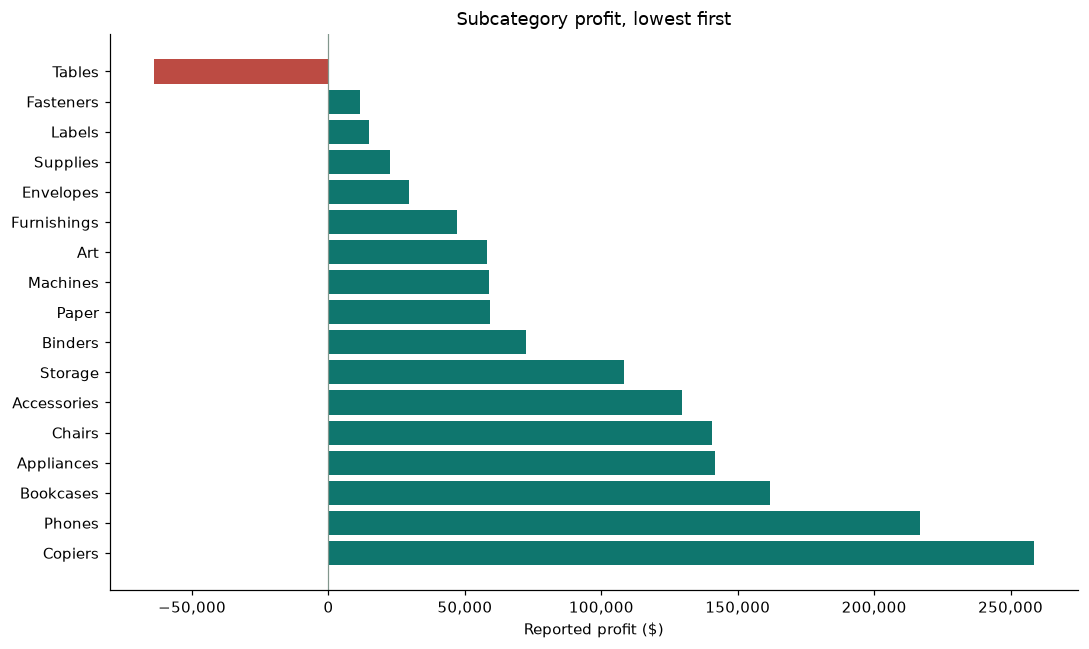

In [6]:
monthly = df.groupby(pd.Grouper(key='Order.Date', freq='MS'))[['Sales', 'Profit']].sum(min_count=1)
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for ax, field, color in zip(axes, ['Sales', 'Profit'], ['#0f766e', '#355c8c']):
    ax.plot(monthly.index, monthly[field], color=color, linewidth=2)
    ax.axhline(0, color='#a7b5b0', linewidth=0.7)
    ax.set_ylabel(f'{field} ($)')
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    ax.grid(axis='y', alpha=0.2)
fig.suptitle('Monthly sales and profit: January 2011–December 2014')
fig.tight_layout()
plt.show()
plt.close(fig)

subcategory = df.groupby('Sub.Category')['Profit'].sum().sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(subcategory.index, subcategory.values, color=['#bc4b43' if x < 0 else '#0f766e' for x in subcategory])
ax.invert_yaxis()
ax.axvline(0, color='#82978d', linewidth=0.8)
ax.set_xlabel('Reported profit ($)')
ax.set_title('Subcategory profit, lowest first')
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
fig.tight_layout()
plt.show()
plt.close(fig)


## 4. Decisions for the app
- Headline metrics: Total Sales, Total Profit, and Profit Margin, recalculated from the selected rows.
- Two supporting charts: monthly sales/profit panels and a ranked subcategory profit chart. The charts show timing and the product groups to investigate.
- Only two filters: Year and Market, matching the director's responsibility and review period.
- Two deliberate exclusions: customer names/rankings (account-level work) and a geographic map (less direct than profit ranking for this decision).
- Proposed production policy: nightly refresh, weekly Monday review. A market with negative total profit in the latest complete month triggers investigation. This is a proposed rule, not a discovered historical policy.
- Data period and intended refresh appear on the page. The demonstration CSV never updates itself. Profit accounting and real-company provenance are not independently verified.

The complete design justification is in [README.md](README.md). A text layout prepared before the application implementation is in [docs/layout.md](docs/layout.md).
